In [1]:
from google.colab import files

uploaded = files.upload()


Saving undetected.zip to undetected.zip
Saving detected.zip to detected.zip


In [2]:
import zipfile
import os

os.makedirs("/content/ANPR_Dataset", exist_ok=True)

for filename in uploaded.keys():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall("/content/ANPR_Dataset")
        print("Extracted:", filename)

print("Dataset extraction completed!")


Extracted: undetected.zip
Extracted: detected.zip
Dataset extraction completed!


In [3]:
import os

base_path = "/content/ANPR_Dataset"

for root, dirs, files_list in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    image_count = sum(
        1 for f in files_list
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    )

    if image_count > 0:
        print(f"{indent}    Images: {image_count}")


ANPR_Dataset/
    undetected/
        2026/
            09/
                24/
                    4/
                        993adb2b-b907-4b37-9101-577de053eda4/
                            Images: 2
                        a80ef495-50b3-4031-a737-319d9893e052/
                            Images: 2
                        87be74da-9f7b-4f19-a9b1-5307b90d180d/
                            Images: 2
                        2c980663-d737-44b3-885f-f2051d0c3dd7/
                            Images: 2
                        a6a973db-38af-411a-8f59-e2aec0c0b9e1/
                            Images: 2
                        6151d541-d959-4aca-9361-ea0ae063760f/
                            Images: 2
                        be964803-a5b4-4181-92b5-43d427f44443/
                            Images: 2
                        b0b0ab7b-3af5-4bf8-9853-ce1e750a7fcd/
                            Images: 2
                        8834e341-7f16-49c0-943b-ffc790775197/
                            Images:

In [4]:
import os
import pandas as pd

base_path = "/content/ANPR_Dataset"

records = []

for root, dirs, files_list in os.walk(base_path):
    for file in files_list:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            full_path = os.path.join(root, file)

            records.append({
                "Folder": root,
                "Image_Name": file,
                "Image_Path": full_path
            })

df = pd.DataFrame(records)

print("Total Images:", len(df))
display(df.head(20))

df.to_csv("/content/image_inventory.csv", index=False)
print("Inventory CSV created!")


Total Images: 3651


,Folder,Image_Name,Image_Path
0,/content/ANPR_Dataset/undetected/2026/09/24/4/...,vehicle.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
1,/content/ANPR_Dataset/undetected/2026/09/24/4/...,full.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
2,/content/ANPR_Dataset/undetected/2026/09/24/4/...,vehicle.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
3,/content/ANPR_Dataset/undetected/2026/09/24/4/...,full.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
4,/content/ANPR_Dataset/undetected/2026/09/24/4/...,vehicle.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
5,/content/ANPR_Dataset/undetected/2026/09/24/4/...,full.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
6,/content/ANPR_Dataset/undetected/2026/09/24/4/...,vehicle.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
7,/content/ANPR_Dataset/undetected/2026/09/24/4/...,full.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
8,/content/ANPR_Dataset/undetected/2026/09/24/4/...,vehicle.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...
9,/content/ANPR_Dataset/undetected/2026/09/24/4/...,full.jpg,/content/ANPR_Dataset/undetected/2026/09/24/4/...


Inventory CSV created!


In [5]:
import os
from collections import Counter

base_path = "/content/ANPR_Dataset"

for category in ["detected", "undetected"]:
    category_path = os.path.join(base_path, category)

    image_count = 0
    case_folders = 0

    for root, dirs, files in os.walk(category_path):
        if "vehicle.jpg" in files or "full.jpg" in files:
            case_folders += 1

        image_count += sum(
            f.lower().endswith((".jpg", ".jpeg", ".png"))
            for f in files
        )

    print(f"\n{category.upper()}")
    print("Cases:", case_folders)
    print("Images:", image_count)



DETECTED
Cases: 745
Images: 2235

UNDETECTED
Cases: 594
Images: 1416


Total vehicle images: 1339


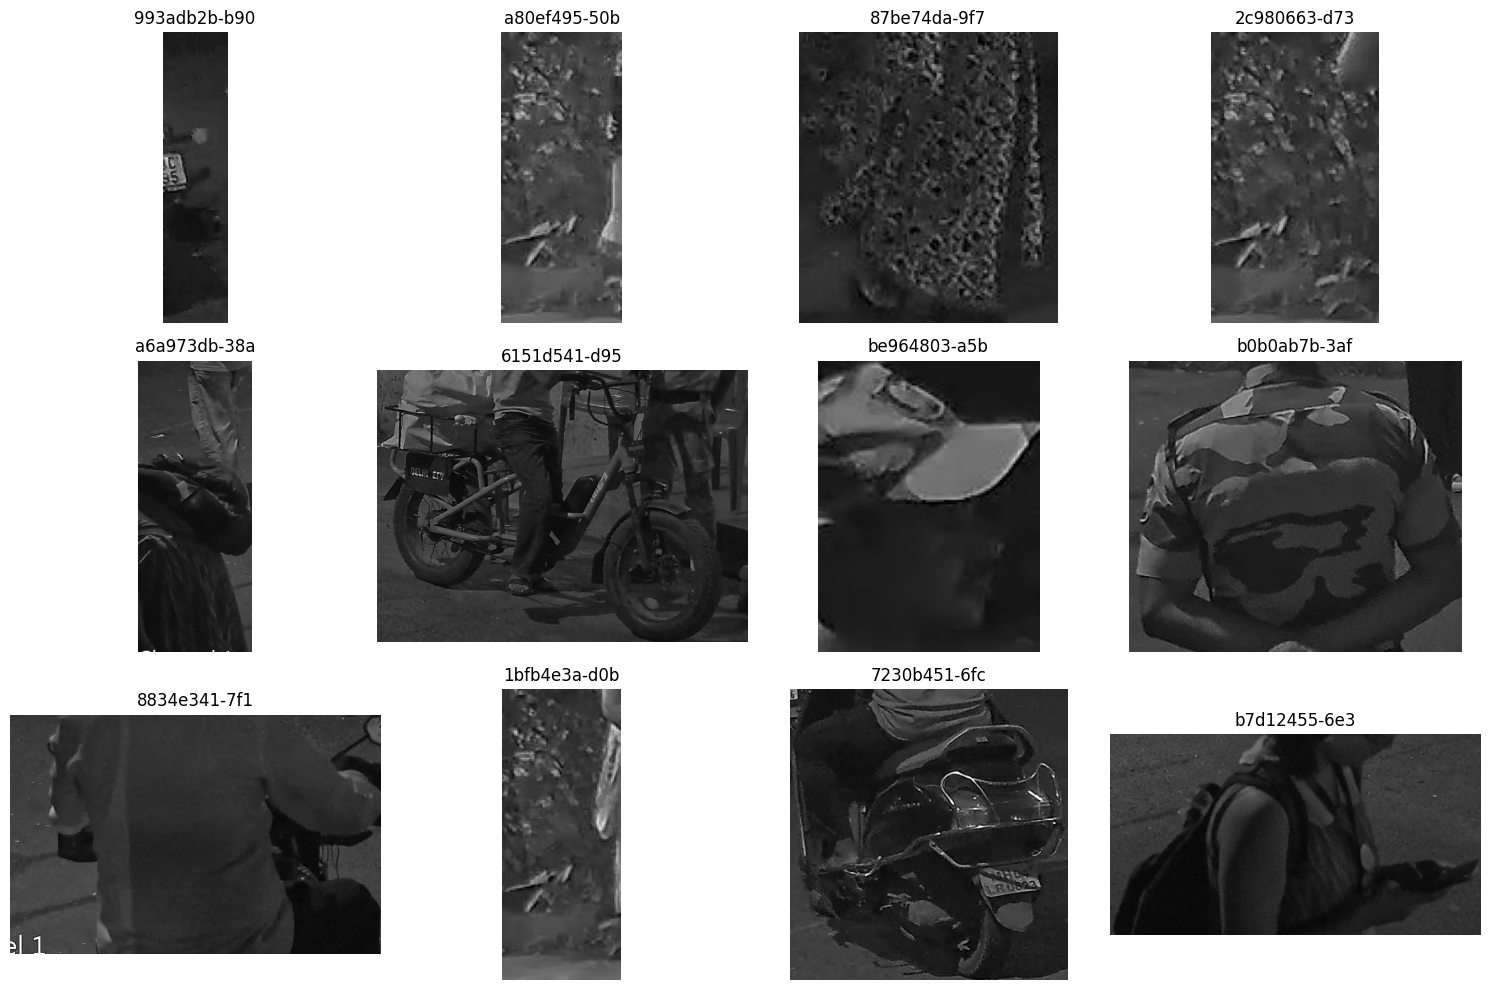

In [6]:

import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/content/ANPR_Dataset"

vehicle_images = glob.glob(
    base_path + "/**/vehicle.jpg",
    recursive=True
)

print("Total vehicle images:", len(vehicle_images))

plt.figure(figsize=(15, 10))

for i, img_path in enumerate(vehicle_images[:12]):
    img = Image.open(img_path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(os.path.dirname(img_path))[:12])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:
import os
import pandas as pd

base_path = "/content/ANPR_Dataset"

# search all case folders
folder_ids = []

for root, dirs, files in os.walk(base_path):
    for folder in dirs:
        folder_path = os.path.join(root, folder)

        if "vehicle.jpg" in os.listdir(folder_path):
            folder_ids.append(folder)

print("Total Case Folders:", len(folder_ids))

print("\nFirst 10 Case IDs:")
print(folder_ids[:10])

Total Case Folders: 1339

First 10 Case IDs:
['993adb2b-b907-4b37-9101-577de053eda4', 'a80ef495-50b3-4031-a737-319d9893e052', '87be74da-9f7b-4f19-a9b1-5307b90d180d', '2c980663-d737-44b3-885f-f2051d0c3dd7', 'a6a973db-38af-411a-8f59-e2aec0c0b9e1', '6151d541-d959-4aca-9361-ea0ae063760f', 'be964803-a5b4-4181-92b5-43d427f44443', 'b0b0ab7b-3af5-4bf8-9853-ce1e750a7fcd', '8834e341-7f16-49c0-943b-ffc790775197', '1bfb4e3a-d0b2-4259-8ec6-de89ed8d29cc']


In [8]:
import glob
import os

excel_files = glob.glob("/content/*.xlsx")

print("Excel Files Found:")
for f in excel_files:
    print(os.path.basename(f))

Excel Files Found:


In [9]:
from google.colab import files
uploaded_excel = files.upload()

Saving export_15.10.2026.xlsx to export_15.10.2026.xlsx


In [10]:
import pandas as pd

excel_path = "/content/export_15.10.2026.xlsx"

xls = pd.ExcelFile(excel_path)

print("Sheet Names:", xls.sheet_names)

df = pd.read_excel(excel_path, sheet_name=0)

print("\nTotal Rows:", len(df))
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

Sheet Names: ['Sheet1']

Total Rows: 162

Column Names:
['Event UUID', 'Captured At', 'Received At', 'Camera', 'Gate', 'Plate', 'Vehicle Type', 'Direction', 'Plate Detection Confidence', 'OCR Confidence', 'Recognition Status', 'Review Status', 'Vehicle Confidence', 'Consistency Score', 'Plate Format Valid', 'Seen Count', 'Latency (ms)', 'Model Version', 'BBox X1', 'BBox Y1', 'BBox X2', 'BBox Y2', 'Full Image Path', 'Vehicle Image Path', 'Plate Image Path', 'Annotated Image Path', 'Processing Sample ID', 'Processing Run ID']


,Event UUID,Captured At,Received At,Camera,Gate,Plate,Vehicle Type,Direction,Plate Detection Confidence,OCR Confidence,...,BBox X1,BBox Y1,BBox X2,BBox Y2,Full Image Path,Vehicle Image Path,Plate Image Path,Annotated Image Path,Processing Sample ID,Processing Run ID
0,3a1609b6-24f2-470a-bd52-54548de361d2,"24 Sep 2026, 7:24:52 PM IST","15 Oct 2026, 4:54:20 PM IST",4,NaN,NaN,Scooter,Both ways,0.0,0.0,...,602.199036,607.958679,1004.875122,1065.416504,undetected/2026/09/24/4/3a1609b6-24f2-470a-bd5...,undetected/2026/09/24/4/3a1609b6-24f2-470a-bd5...,NaN,NaN,08524631-0db1-4ea2-8be9-cc473736d99b,9363063e-7d99-4414-aa2e-34aee45b55c5
1,0f509ad2-9b9f-4f37-a51f-a5ee92fe9c7c,"24 Sep 2026, 7:24:47 PM IST","15 Oct 2026, 4:54:15 PM IST",4,NaN,NaN,Scooter,Both ways,0.0,0.0,...,1712.527954,482.651001,1920.119019,1368.345825,undetected/2026/09/24/4/0f509ad2-9b9f-4f37-a51...,undetected/2026/09/24/4/0f509ad2-9b9f-4f37-a51...,NaN,NaN,3deebe23-1c88-475b-9550-df360907131f,9363063e-7d99-4414-aa2e-34aee45b55c5
2,b2d3be56-0d11-46bf-9148-ea6f57992b70,"24 Sep 2026, 7:24:45 PM IST","15 Oct 2026, 4:54:12 PM IST",4,NaN,NaN,Scooter,Both ways,0.0,0.0,...,-0.181515,110.422119,129.541351,357.944550,undetected/2026/09/24/4/b2d3be56-0d11-46bf-914...,undetected/2026/09/24/4/b2d3be56-0d11-46bf-914...,NaN,NaN,3deebe23-1c88-475b-9550-df360907131f,9363063e-7d99-4414-aa2e-34aee45b55c5
3,b7d12455-6e3f-4fc6-a933-14dcf1ec0f9e,"24 Sep 2026, 7:24:40 PM IST","15 Oct 2026, 4:54:08 PM IST",4,NaN,NaN,Scooter,Both ways,0.0,0.0,...,727.876648,697.658569,1400.855835,1062.668091,undetected/2026/09/24/4/b7d12455-6e3f-4fc6-a93...,undetected/2026/09/24/4/b7d12455-6e3f-4fc6-a93...,NaN,NaN,3deebe23-1c88-475b-9550-df360907131f,9363063e-7d99-4414-aa2e-34aee45b55c5
4,98419551-fd73-41e3-a4e8-a718974d925c,"24 Sep 2026, 7:23:57 PM IST","15 Oct 2026, 4:53:26 PM IST",4,NaN,NaN,Scooter,Both ways,0.0,0.0,...,0.014328,374.341827,309.145325,1042.397827,undetected/2026/09/24/4/98419551-fd73-41e3-a4e...,undetected/2026/09/24/4/98419551-fd73-41e3-a4e...,NaN,NaN,b9c29880-04b7-4a37-8f53-558d77812855,9363063e-7d99-4414-aa2e-34aee45b55c5


In [12]:
import pandas as pd
import os

excel_path = "/content/export_15.10.2026.xlsx"
base_path = "/content/ANPR_Dataset"

df = pd.read_excel(excel_path)

# Folder IDs
folder_map = {}

for root, dirs, files in os.walk(base_path):
    for folder in dirs:
        folder_path = os.path.join(root, folder)

        if "vehicle.jpg" in os.listdir(folder_path):
            folder_map[folder] = folder_path

# Excel UUID or folder matching
df["Matched Folder"] = df["Event UUID"].astype(str).map(folder_map)

print("Total Excel Rows:", len(df))
print("Matched Cases:", df["Matched Folder"].notna().sum())
print("Unmatched Cases:", df["Matched Folder"].isna().sum())

display(df[["Event UUID", "Vehicle Type", "Matched Folder"]].head(10))

Total Excel Rows: 162
Matched Cases: 159
Unmatched Cases: 3


,Event UUID,Vehicle Type,Matched Folder
0,3a1609b6-24f2-470a-bd52-54548de361d2,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
1,0f509ad2-9b9f-4f37-a51f-a5ee92fe9c7c,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
2,b2d3be56-0d11-46bf-9148-ea6f57992b70,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
3,b7d12455-6e3f-4fc6-a933-14dcf1ec0f9e,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
4,98419551-fd73-41e3-a4e8-a718974d925c,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
5,71057970-d4c0-4e30-851a-0765dbaee681,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
6,5701f971-758d-44ef-b4b4-a4cb347c5281,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
7,0b841efd-fb4f-44cf-b72e-07469993209e,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
8,e5dfd2f1-0036-44fa-8f89-80928f3937a7,Scooter,/content/ANPR_Dataset/undetected/2026/09/24/4/...
9,8fa3110d-83b2-4c08-8e12-db5882c3ddbf,Motorcycle,/content/ANPR_Dataset/undetected/2026/09/24/4/...


In [13]:
unmatched = df[df["Matched Folder"].isna()]

print("Unmatched Case IDs:")
display(unmatched[["Event UUID", "Vehicle Type"]])

Unmatched Case IDs:


,Event UUID,Vehicle Type
44,4c3c7605-020a-4f10-a1ef-e0bb179eca33,Scooter
103,881eee9b-bd92-4503-92fe-f20085cf0658,Scooter
130,b2a2a134-e848-4460-8c51-29ea5dcbb9d5,Scooter


In [14]:
import os

missing_ids = [
    "4c3c7605-020a-4f10-a1ef-e0bb179eca33",
    "881eee9b-bd92-4503-92fe-f20085cf0658",
    "b2a2a134-e848-4460-8c51-29ea5dcbb9d5"
]

base_path = "/content/ANPR_Dataset"

for case_id in missing_ids:
    found = False

    for root, dirs, files in os.walk(base_path):
        if case_id in root:
            print("\nCase ID:", case_id)
            print("Folder:", root)
            print("Files:", files)
            found = True

    if not found:
        print("\nNot Found:", case_id)


Not Found: 4c3c7605-020a-4f10-a1ef-e0bb179eca33

Not Found: 881eee9b-bd92-4503-92fe-f20085cf0658

Not Found: b2a2a134-e848-4460-8c51-29ea5dcbb9d5


In [15]:
import os

for index, row in df[df["Matched Folder"].notna()].head(5).iterrows():

    folder = row["Matched Folder"]

    print("\nCase ID:", row["Event UUID"])
    print("Vehicle Type:", row["Vehicle Type"])

    for image_name in ["full.jpg", "vehicle.jpg"]:
        image_path = os.path.join(folder, image_name)

        print(image_name, "Exists:", os.path.exists(image_path))


Case ID: 3a1609b6-24f2-470a-bd52-54548de361d2
Vehicle Type: Scooter
full.jpg Exists: True
vehicle.jpg Exists: True

Case ID: 0f509ad2-9b9f-4f37-a51f-a5ee92fe9c7c
Vehicle Type: Scooter
full.jpg Exists: True
vehicle.jpg Exists: True

Case ID: b2d3be56-0d11-46bf-9148-ea6f57992b70
Vehicle Type: Scooter
full.jpg Exists: True
vehicle.jpg Exists: True

Case ID: b7d12455-6e3f-4fc6-a933-14dcf1ec0f9e
Vehicle Type: Scooter
full.jpg Exists: True
vehicle.jpg Exists: True

Case ID: 98419551-fd73-41e3-a4e8-a718974d925c
Vehicle Type: Scooter
full.jpg Exists: True
vehicle.jpg Exists: True


In [16]:
!pip install openpyxl pillow -q

import pandas as pd
import os
from openpyxl import Workbook
from openpyxl.drawing.image import Image as XLImage
from openpyxl.styles import Font, Alignment, PatternFill
from openpyxl.utils import get_column_letter
from PIL import Image as PILImage

# Output workbook
wb = Workbook()
ws = wb.active
ws.title = "ANPR Cases"

# Columns
headers = [
    "Event UUID",
    "Vehicle Type",
    "Plate",
    "OCR Confidence",
    "Full Image",
    "Vehicle Image",
    "Match Status"
]

ws.append(headers)

for index, row in df.iterrows():

    folder = row["Matched Folder"]

    ws.append([
        row["Event UUID"],
        row["Vehicle Type"],
        row["Plate"],
        row["OCR Confidence"],
        "",
        "",
        "Matched" if pd.notna(folder) else "Unmatched"
    ])

    excel_row = ws.max_row

    if pd.notna(folder):
        for col, filename in [(5, "full.jpg"), (6, "vehicle.jpg")]:
            image_path = os.path.join(folder, filename)

            if os.path.exists(image_path):
                img = PILImage.open(image_path)
                img.thumbnail((180, 110))

                temp_path = f"/content/temp_{index}_{filename}"
                img.save(temp_path)

                excel_img = XLImage(temp_path)
                ws.add_image(excel_img, f"{get_column_letter(col)}{excel_row}")

    ws.row_dimensions[excel_row].height = 90

# Column widths
widths = [42, 18, 18, 18, 25, 25, 18]

for i, width in enumerate(widths, start=1):
    ws.column_dimensions[get_column_letter(i)].width = width

# Header formatting
for cell in ws[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = PatternFill("solid", fgColor="164B60")
    cell.alignment = Alignment(horizontal="center")

ws.freeze_panes = "A2"

output_path = "/content/ANPR_Cases_With_Images.xlsx"
wb.save(output_path)

print("Excel created successfully!")
print("Total Cases:", len(df))
print("Matched:", df["Matched Folder"].notna().sum())
print("Unmatched:", df["Matched Folder"].isna().sum())
print("File:", output_path)

Excel created successfully!
Total Cases: 162
Matched: 159
Unmatched: 3
File: /content/ANPR_Cases_With_Images.xlsx


In [17]:
from google.colab import files

files.download("/content/ANPR_Cases_With_Images.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import pandas as pd

df = pd.read_excel("/content/export_15.10.2026.xlsx")

# Vehicle Type नुसार cases मोजणे
vehicle_count = df["Vehicle Type"].value_counts(dropna=False)

print("Vehicle Type Wise Case Count:")
print(vehicle_count)

print("\nTotal Cases:", len(df))

Vehicle Type Wise Case Count:
Vehicle Type
Scooter          86
Motorcycle       62
Auto-rickshaw    14
Name: count, dtype: int64

Total Cases: 162


In [19]:
import pandas as pd

df = pd.read_excel("/content/export_15.10.2026.xlsx")

main_df = df[df["Vehicle Type"].isin(["Scooter", "Motorcycle"])]

summary = main_df.groupby("Vehicle Type").agg(
    Total_Cases=("Event UUID", "count"),
    Avg_Vehicle_Confidence=("Vehicle Confidence", "mean"),
    Avg_OCR_Confidence=("OCR Confidence", "mean"),
    Avg_Plate_Detection=("Plate Detection Confidence", "mean")
).round(3)

display(summary)

,Total_Cases,Avg_Vehicle_Confidence,Avg_OCR_Confidence,Avg_Plate_Detection
Vehicle Type,,,,
Motorcycle,62,0.499,0.178,0.272
Scooter,86,0.526,0.221,0.312


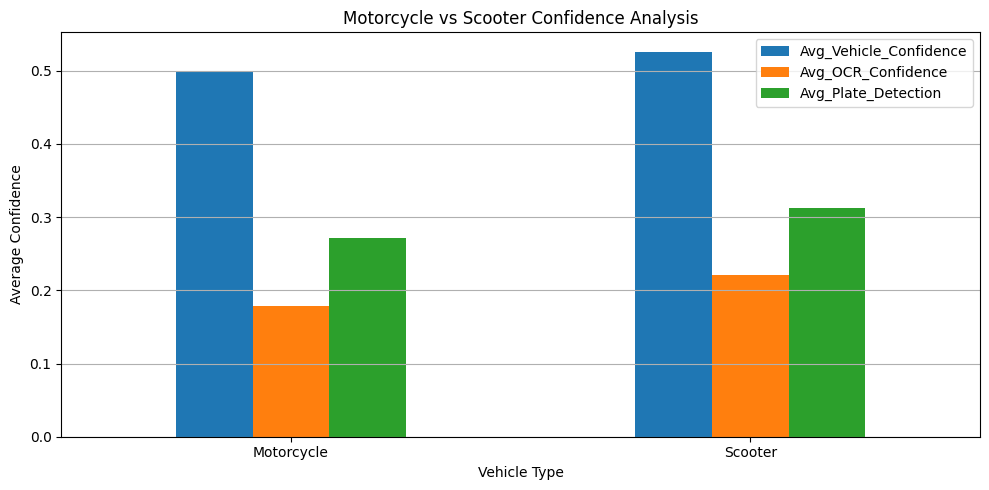

In [20]:
import matplotlib.pyplot as plt

summary[[
    "Avg_Vehicle_Confidence",
    "Avg_OCR_Confidence",
    "Avg_Plate_Detection"
]].plot(kind="bar", figsize=(10, 5))

plt.title("Motorcycle vs Scooter Confidence Analysis")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Confidence")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [21]:
import pandas as pd

df = pd.read_excel("/content/export_15.10.2026.xlsx")

main_df = df[
    df["Vehicle Type"].isin(["Motorcycle", "Scooter"])
]

recognition_summary = pd.crosstab(
    main_df["Vehicle Type"],
    main_df["Recognition Status"]
)

display(recognition_summary)

Recognition Status,Low confidence,No plate,Recognized,Unreadable
Vehicle Type,,,,
Motorcycle,9,44,4,5
Scooter,8,56,12,10


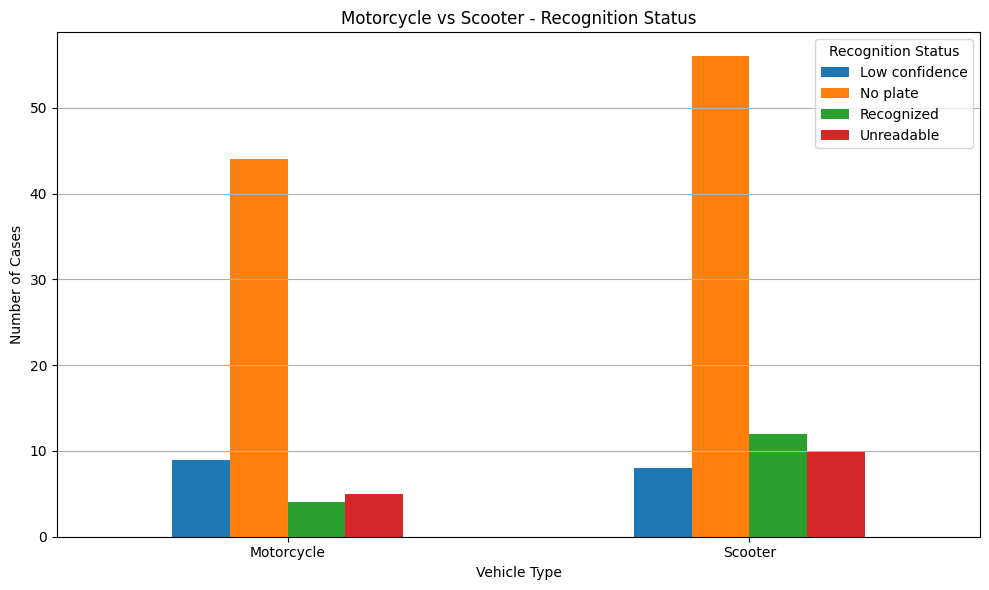

In [22]:
import matplotlib.pyplot as plt

recognition_summary.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Motorcycle vs Scooter - Recognition Status")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.legend(title="Recognition Status")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [23]:
direction_summary = pd.crosstab(
    main_df["Vehicle Type"],
    main_df["Direction"])

display(direction_summary)

Direction,Both ways
Vehicle Type,
Motorcycle,62
Scooter,86


In [24]:
recognition_summary = pd.crosstab(
    main_df["Vehicle Type"],
    main_df["Recognition Status"]
)

display(recognition_summary)

Recognition Status,Low confidence,No plate,Recognized,Unreadable
Vehicle Type,,,,
Motorcycle,9,44,4,5
Scooter,8,56,12,10


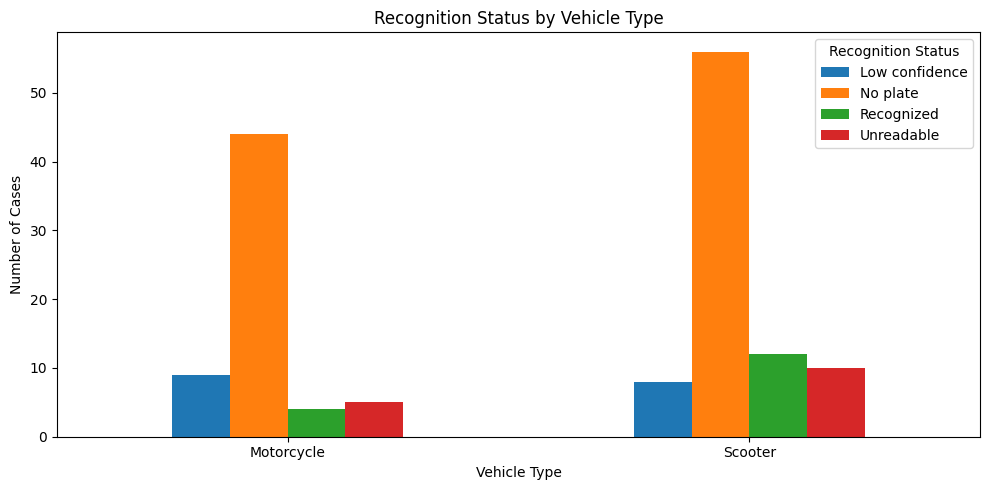

In [25]:
recognition_summary.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Recognition Status by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.legend(title="Recognition Status")
plt.tight_layout()
plt.show()

In [26]:
confidence_summary = main_df.groupby("Vehicle Type")[
    [
        "Plate Detection Confidence",
        "OCR Confidence",
        "Vehicle Confidence"
    ]
].mean()

display(confidence_summary.round(3))

,Plate Detection Confidence,OCR Confidence,Vehicle Confidence
Vehicle Type,,,
Motorcycle,0.272,0.178,0.499
Scooter,0.312,0.221,0.526


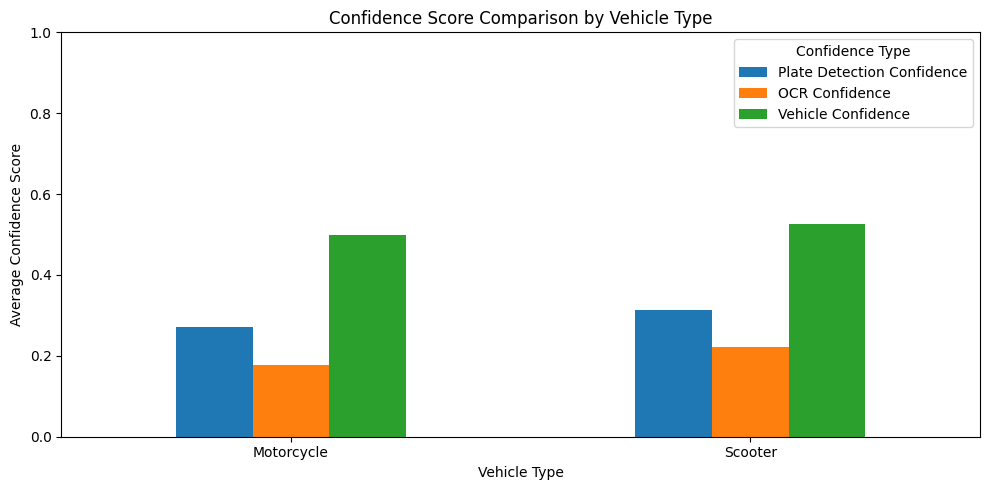

In [27]:
confidence_summary.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Confidence Score Comparison by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Confidence Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Confidence Type")
plt.tight_layout()
plt.show()

In [28]:
consistency_summary = main_df.groupby("Vehicle Type")[
    "Consistency Score"
].mean()

display(consistency_summary.round(3))

,Consistency Score
Vehicle Type,
Motorcycle,0.133
Scooter,0.178


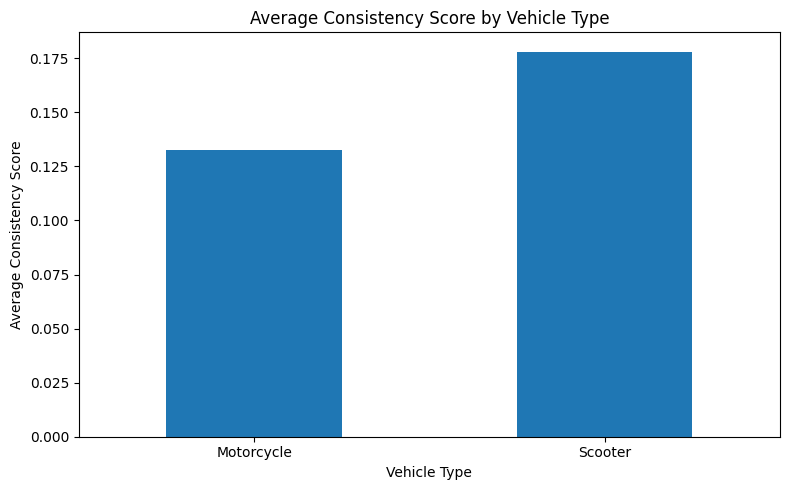

In [29]:
consistency_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Consistency Score by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Consistency Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
plate_format_summary = pd.crosstab(
    main_df["Vehicle Type"],
    main_df["Plate Format Valid"]
)

display(plate_format_summary)

Plate Format Valid,NO,YES
Vehicle Type,,
Motorcycle,4,14
Scooter,4,26


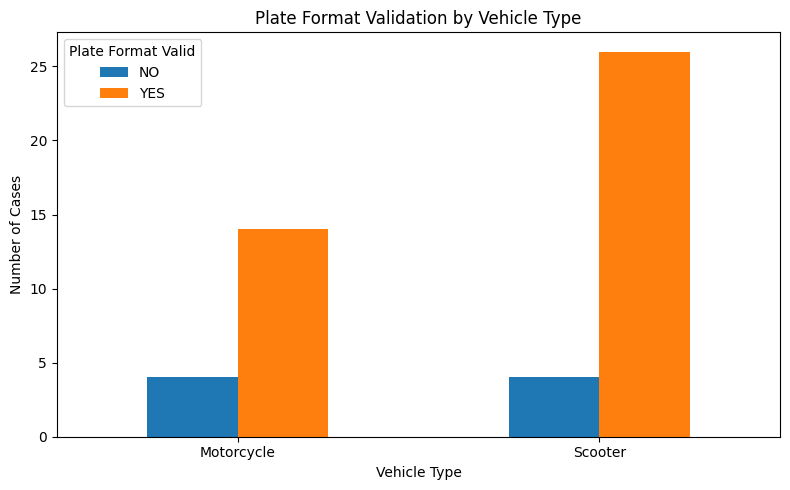

In [31]:
plate_format_summary.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Plate Format Validation by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Number of Cases")
plt.xticks(rotation=0)
plt.legend(title="Plate Format Valid")
plt.tight_layout()
plt.show()

In [32]:
print("Missing Values:")
print(main_df[
    ["Plate Format Valid", "Consistency Score",
     "Plate Detection Confidence", "OCR Confidence",
     "Vehicle Confidence"]
].isnull().sum())

Missing Values:
Plate Format Valid            100
Consistency Score               0
Plate Detection Confidence      0
OCR Confidence                  0
Vehicle Confidence              0
dtype: int64


In [33]:
recognition_percentage = pd.crosstab(
    main_df["Vehicle Type"],
    main_df["Recognition Status"],
    normalize="index"
) * 100

display(recognition_percentage.round(2))

Recognition Status,Low confidence,No plate,Recognized,Unreadable
Vehicle Type,,,,
Motorcycle,14.52,70.97,6.45,8.06
Scooter,9.30,65.12,13.95,11.63


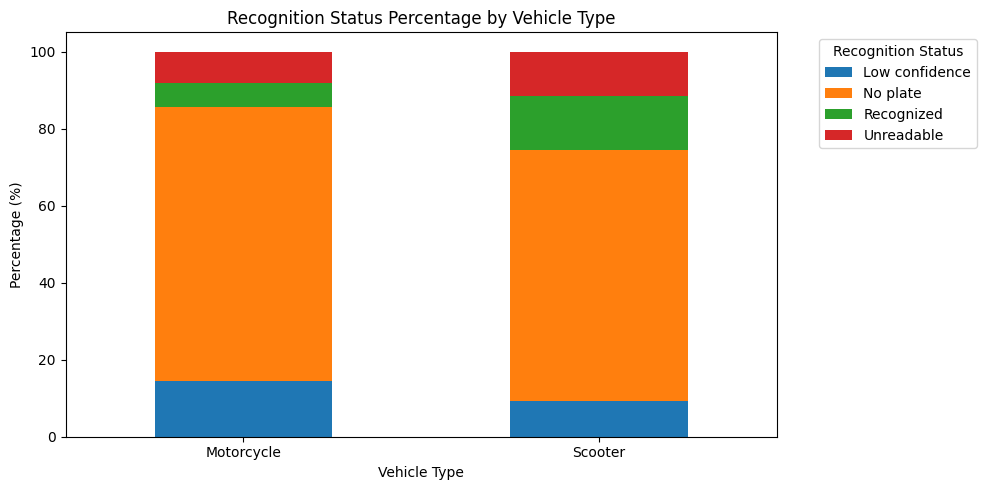

In [34]:
recognition_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Recognition Status Percentage by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Recognition Status", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [35]:
final_summary = main_df.groupby("Vehicle Type").agg(
    Total_Cases=("Vehicle Type", "count"),
    Recognized_Cases=("Recognition Status",
                      lambda x: (x == "Recognized").sum()),
    No_Plate=("Recognition Status",
              lambda x: (x == "No plate").sum()),
    Low_Confidence=("Recognition Status",
                    lambda x: (x == "Low confidence").sum()),
    Unreadable=("Recognition Status",
                lambda x: (x == "Unreadable").sum()),
    Avg_Plate_Confidence=("Plate Detection Confidence", "mean"),
    Avg_OCR_Confidence=("OCR Confidence", "mean"),
    Avg_Vehicle_Confidence=("Vehicle Confidence", "mean"),
    Avg_Consistency=("Consistency Score", "mean")
)

display(final_summary.round(3))

,Total_Cases,Recognized_Cases,No_Plate,Low_Confidence,Unreadable,Avg_Plate_Confidence,Avg_OCR_Confidence,Avg_Vehicle_Confidence,Avg_Consistency
Vehicle Type,,,,,,,,,
Motorcycle,62,4,44,9,5,0.272,0.178,0.499,0.133
Scooter,86,12,56,8,10,0.312,0.221,0.526,0.178


In [36]:
print("ANPR PROJECT - FINAL CONCLUSION")
print("--------------------------------")

print("Total Cases:", len(main_df))
print("Motorcycle Cases:",
      (main_df["Vehicle Type"] == "Motorcycle").sum())
print("Scooter Cases:",
      (main_df["Vehicle Type"] == "Scooter").sum())

print("\nKey Findings:")
print("1. Scooter has higher average confidence scores.")
print("2. No plate is the most common recognition status.")
print("3. Scooter recognition rate is higher than Motorcycle.")
print("4. OCR confidence is relatively low for both vehicles.")
print("5. Plate Format Valid has 100 missing values.")

ANPR PROJECT - FINAL CONCLUSION
--------------------------------
Total Cases: 148
Motorcycle Cases: 62
Scooter Cases: 86

Key Findings:
1. Scooter has higher average confidence scores.
2. No plate is the most common recognition status.
3. Scooter recognition rate is higher than Motorcycle.
4. OCR confidence is relatively low for both vehicles.
5. Plate Format Valid has 100 missing values.
